In [17]:
import numpy as np
import matplotlib.pyplot as plt


from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline


from sklearn.metrics import (

                             accuracy_score,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             classification_report,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             RocCurveDisplay


                            )


In [18]:
iris=datasets.load_iris()

FEATURE EXTRACTION


In [19]:
x=iris.data[ :,:2]
y=iris.target

In [20]:
mask = y !=2
x=x[mask]
y=y[mask]

In [21]:
print("feature names:", iris.feature_names)
print("dataset shape:", x.shape)
print("target names:", iris.target_names[:2])

feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
dataset shape: (100, 2)
target names: ['setosa' 'versicolor']


In [22]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25,
                         random_state=42, stratify=y) #stratify gives us the difference between linear and logistic regression

In [23]:
model=make_pipeline(StandardScaler(),
                    SVC(kernel="linear", C=1.0))

In [24]:
model.fit(x_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(kernel='linear'))])

In [25]:
y_pred=model.predict(x_test)

In [31]:
y_score=model.decision_function(x_test)
y_score

array([ 0.63166843,  2.47370942,  1.73695051, -1.36847528,  2.78934007,
        0.31575039,  0.15764766,  0.84208887,  2.42096062,  2.3158941 ,
       -2.94749072,  0.89455028, -1.78931615, -2.00002398,  1.42103246,
       -1.73685474, -1.89467006,  3.73695052, -2.31594203, -3.68424964,
       -1.42093669, -1.42108039, -0.94734701, -1.4736855 ,  1.47349387])

In [30]:
print(f"accuracy: {accuracy_score(y_test, y_pred)}")
print(f"precision: {precision_score(y_test, y_pred)}")


accuracy: 0.96
precision: 0.9230769230769231


In [32]:
print(f"recall: {recall_score(y_test, y_pred)}")
print(f"f1 score: {f1_score(y_test, y_pred)}")

recall: 1.0
f1 score: 0.96


In [41]:
print("\nClassification Report\n")
print(classification_report(y_test, y_pred))


Classification Report

              precision    recall  f1-score   support

           0       1.00      0.92      0.96        13
           1       0.92      1.00      0.96        12

    accuracy                           0.96        25
   macro avg       0.96      0.96      0.96        25
weighted avg       0.96      0.96      0.96        25



In [38]:
cm=confusion_matrix(y_test, y_pred)
print(cm)


[[12  1]
 [ 0 12]]


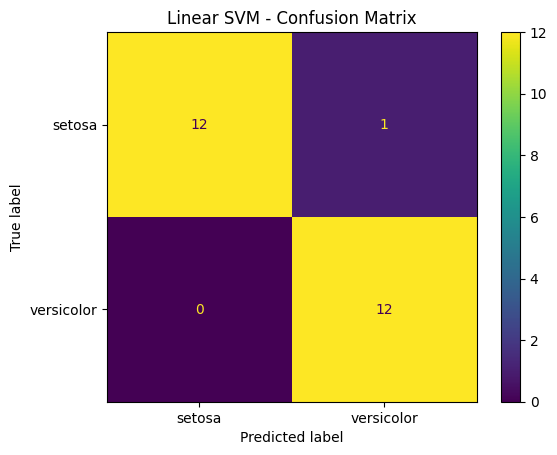

In [44]:
ConfusionMatrixDisplay(cm, display_labels=iris.target_names[:2]).plot()
plt.title("Linear SVM - Confusion Matrix")
plt.tight_layout
plt.show()
#SVM IS ALSO CALLED LARGE MARGIN CLASSIFIER

pipeline extraction

In [45]:
scaler=model.named_steps["standardscaler"]
svc=model.named_steps["svc"]

In [46]:
x1_min, x1_max=x[:,0].min()-0.5, x[:,0].max()+0.5
x2_min, x2_max=x[:,1].min()-0.5, x[:,1].max()+0.5

In [47]:
xx,yy=np.meshgrid(
    np.linspace(x1_min, x1_max, 100),
    np.linspace(x2_min, x2_max, 100)
)

In [50]:
grid=np.c_[xx.ravel(), yy.ravel()]

#cal decision score at grid point
z=model.decision_function(grid)
#reshape
z=z.reshape(xx.shape)

In [52]:
plt.figure(figsize=(9,6))
plt.scatter(
    x_train
)

<Figure size 900x600 with 0 Axes>

<Figure size 900x600 with 0 Axes>

NameError: name 'svm_model' is not defined

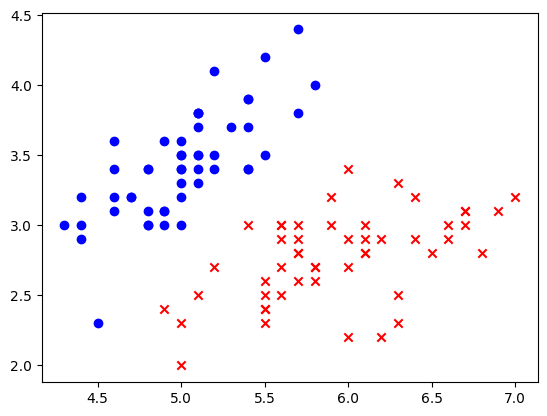

In [58]:
from os import supports_bytes_environ
plt.scatter(
    x[y==0,0],x[y==0,1],
    c="blue", marker="o", label="class 0"
)
plt.scatter(
    x[y==1,0],x[y==1,1],
    c="red", marker="x", label="class 1"
)

#hightlisht support vectors

support_vectors_original=scaler.inverse_transform(svm_model.support_vectors_)

NameError: name 'svm_model' is not defined

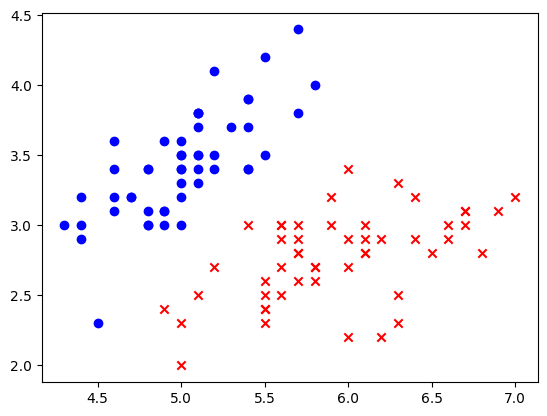

In [59]:
import matplotlib.pyplot as plt
from os import supports_bytes_environ

# 1. Plot the original dataset points
plt.scatter(
    x[y==0, 0], x[y==0, 1],
    c="blue", marker="o", label="class 0"
)
plt.scatter(
    x[y==1, 0], x[y==1, 1],
    c="red", marker="x", label="class 1"
)

# 2. Extract and inverse-transform the support vectors
support_vectors_original = scaler.inverse_transform(svm_model.support_vectors_)

# 3. Highlight the support vectors
plt.scatter(
    support_vectors_original[:, 0], support_vectors_original[:, 1],
    s=150,                     # Make the marker size larger to encircle the points
    facecolors="none",         # Leave the inside hollow so the original color shows
    edgecolors="black",        # Draw a sharp black outline around them
    linewidths=1.5,            # Set the thickness of the outline
    label="Support Vectors"    # Add to the legend
)

# 4. Finalise the plot
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(loc="best")
plt.show()
